In [3]:

import tensorflow as tf
from tensorflow.keras import layers, models


In [4]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()

In [5]:
x_train=x_train.reshape(-1,28,28,1)/255.0
x_test=x_test.reshape(-1,28,28,1)/255.0

In [6]:
model=models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])

c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
model.fit(x_train,y_train,epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.9585 - loss: 0.1384
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9853 - loss: 0.0475
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9904 - loss: 0.0298


In [9]:
l,a=model.evaluate(x_test,y_test)
a

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9863 - loss: 0.0423


0.986299991607666

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


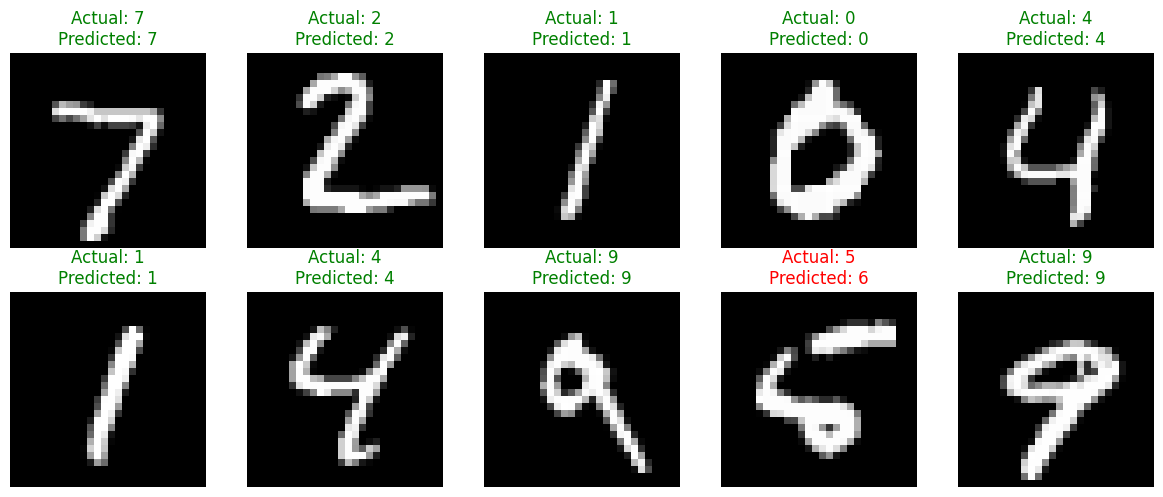

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Predict test images
predictions = model.predict(x_test)

# Get predicted digit (highest probability)
predicted_labels = np.argmax(predictions, axis=1)

# Display 10 images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    actual = y_test[i]
    predicted = predicted_labels[i]
    if actual==predicted: 
            colour='green'
    else:
            colour='red'
    plt.title(f"Actual: {actual}\nPredicted: {predicted}",color=colour)

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
for i in range(10):
    print(
        "Actual:", y_test[i],
        "Predicted:", predicted_labels[i],
        "Correct:", y_test[i] == predicted_labels[i]
    )

Actual: 7 Predicted: 7 Correct: True
Actual: 2 Predicted: 2 Correct: True
Actual: 1 Predicted: 1 Correct: True
Actual: 0 Predicted: 0 Correct: True
Actual: 4 Predicted: 4 Correct: True
Actual: 1 Predicted: 1 Correct: True
Actual: 4 Predicted: 4 Correct: True
Actual: 9 Predicted: 9 Correct: True
Actual: 5 Predicted: 6 Correct: False
Actual: 9 Predicted: 9 Correct: True
